# 4. Modelo no lineal: random forest

El diagnóstico del capítulo 3 mostró que el SVR lineal **no anticipa los aguaceros**: sus residuos tienen asimetría cercana a 4 y media positiva, es decir, subestima las semanas muy lluviosas. Un modelo lineal no puede representar relaciones como "si el suelo ya está húmedo **y** es temporada de lluvias, la semana siguiente puede traer un aguacero". El **random forest** promedia muchos árboles de decisión, cada uno capaz de capturar ese tipo de interacciones y umbrales, sin suponer una forma funcional.

**Diseño (idéntico al del capítulo 3, para que la comparación sea justa):**

- Mismas 26 predictoras, todas del pasado con 3 días de latencia, más los armónicos del calendario.
- Misma partición cronológica con purga (entrenamiento 1981–2020, prueba 2021–2025) y misma validación cruzada de ventana creciente con separación de 7h + 3 días.
- Imputación por mediana dentro del `Pipeline`. El random forest no necesita escalado.
- **Control del sobreajuste:** la profundidad máxima de los árboles (`max_depth`), el mínimo de semanas por hoja (`min_samples_leaf`) y la fracción de predictoras por división (`max_features`) se eligen por validación cruzada temporal. La prueba se usa una sola vez.
- **Semanas de aguacero:** semanas con lluvia por encima del percentil 90 del **entrenamiento** (el umbral no mira la prueba).

In [2]:
import sys, warnings, time
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import Pipeline

from src import config as cfg, modelado as md
np.random.seed(cfg.SEED)
plt.rcParams["figure.dpi"] = 110

df = pd.read_csv(cfg.DATA_PROCESSED / cfg.ARCHIVO_DATOS, parse_dates=["fecha"])
rmse = lambda a, b: float(np.sqrt(mean_squared_error(a, b)))


def pipeline_rf(max_depth=None, min_samples_leaf=5, max_features=1.0, n_estimators=200):
    return Pipeline([("imputar", SimpleImputer(strategy="median")),
                     ("rf", RandomForestRegressor(n_estimators=n_estimators, max_depth=max_depth,
                                                  min_samples_leaf=min_samples_leaf, max_features=max_features,
                                                  random_state=cfg.SEED, n_jobs=-1))])


GRILLA = [dict(max_depth=d, min_samples_leaf=l, max_features=f)
          for d in (4, 8, None) for l in (5, 20, 50) for f in (0.33, 1.0)]
print(f"Combinaciones de hiperparámetros: {len(GRILLA)} × {cfg.N_SPLITS_CV} folds por horizonte")

Combinaciones de hiperparámetros: 18 × 5 folds por horizonte


## 4.1 Evaluación por horizonte

In [4]:
filas, cvs, AJ = [], [], {}
for h in cfg.HORIZONTES_SEMANAS:
    t0 = time.time()
    tabla = md.tabla_modelado(df, h)
    cols = md.columnas_predictoras(tabla)
    tr, te = md.particion_cronologica(tabla, h)
    tr = tr.sort_values("fecha").reset_index(drop=True)
    te = te.sort_values("fecha").reset_index(drop=True)
    sp = list(md.cv_temporal(tr.fecha, gap_dias=cfg.DIAS_POR_SEMANA * h + cfg.LATENCIA_DIAS))

    # Búsqueda de hiperparámetros del random forest con validación cruzada temporal
    g = []
    for p in GRILLA:
        e = [rmse(tr.loc[b, "y"], pipeline_rf(**p).fit(tr.loc[a, cols], tr.loc[a, "y"]).predict(tr.loc[b, cols])) for a, b in sp]
        g.append({**p, "RMSE_cv": np.mean(e)})
    g = pd.DataFrame(g).sort_values("RMSE_cv").reset_index(drop=True)
    mejor = {k: (None if pd.isna(v) else (int(v) if k != "max_features" else float(v))) for k, v in g.iloc[0][["max_depth", "min_samples_leaf", "max_features"]].items()}
    rf = pipeline_rf(**mejor).fit(tr[cols], tr.y)

    # SVR del capítulo 3 (misma función, mismos datos) para comparar semana a semana
    svr, mj, _, _ = md.ajustar_svr(tr, cols, sp)

    # Habilidad en validación cruzada y residuos del último fold (intervalos conformales)
    ss = []
    for a, b in sp:
        m = pipeline_rf(**mejor).fit(tr.loc[a, cols], tr.loc[a, "y"])
        ss.append(1 - rmse(tr.loc[b, "y"], m.predict(tr.loc[b, cols])) / rmse(tr.loc[b, "y"], md.climatologia(tr.loc[a], h=h)(tr.loc[b])))
    cal = md.cuantiles_conformales(tr.loc[b, "y"], m.predict(tr.loc[b, cols]), niveles=(0.025, 0.05, 0.5, 0.95, 0.975))

    p_rf, p_svr, clim = rf.predict(te[cols]), svr.predict(te[cols]), md.climatologia(tr, h=h)(te)
    bloque = max(8, h + 4)
    for nombre, yhat in [("Climatología", clim), ("Persistencia semanal", te.base_persistencia.values), ("SVR lineal", p_svr), ("Random forest", p_rf)]:
        m_ = md.metricas(te.y, yhat)
        ci = md.bootstrap_bloques(te.y.values, yhat, clim, largo_bloque=bloque, n_boot=1000)
        filas.append({"h": h, "modelo": nombre, "RMSE": m_["RMSE"], "MAE": m_["MAE"], "R2": m_["R2"],
                      "SS": 1 - m_["RMSE"] / rmse(te.y, clim), "SS_inf": ci.loc["SS_clim", "inf"], "SS_sup": ci.loc["SS_clim", "sup"]})
    # Diferencia RF frente a SVR con IC por bloques: skill del RF usando el SVR como referencia
    ci_rs = md.bootstrap_bloques(te.y.values, p_rf, p_svr, largo_bloque=bloque, n_boot=1000)
    q = md.aplicar_intervalo(p_rf, cal)
    cvs.append({"h": h, **mejor, "RMSE_cv": g.iloc[0].RMSE_cv, "SS_cv_media": np.mean(ss), "folds_positivos": int((np.array(ss) > 0).sum()),
                "SS_RF_vs_SVR": 1 - rmse(te.y, p_rf) / rmse(te.y, p_svr),
                "IC_inf": ci_rs.loc["SS_clim", "inf"], "IC_sup": ci_rs.loc["SS_clim", "sup"],
                "cobertura_95": float(np.mean((te.y >= q[0.025]) & (te.y <= q[0.975])))})
    AJ[h] = dict(rf=rf, svr=svr, cols=cols, tr=tr, te=te.assign(rf=p_rf, svr=p_svr, clim=clim), grilla=g, mejor=mejor, sp=sp, cal=cal)
    print(f"h = {h:>2}: {mejor} ({time.time() - t0:.0f} s)")

res = pd.DataFrame(filas); cv = pd.DataFrame(cvs)
res.to_csv(cfg.DATA_PROCESSED / "resultados_random_forest.csv", index=False)
res.pivot(index="h", columns="modelo", values="RMSE")[["Climatología", "Persistencia semanal", "SVR lineal", "Random forest"]].round(2)

h =  1: {'max_depth': 8, 'min_samples_leaf': 5, 'max_features': 0.33} (67 s)
h =  2: {'max_depth': None, 'min_samples_leaf': 5, 'max_features': 0.33} (66 s)
h =  4: {'max_depth': None, 'min_samples_leaf': 20, 'max_features': 1.0} (69 s)
h =  8: {'max_depth': 8, 'min_samples_leaf': 20, 'max_features': 1.0} (70 s)
h = 13: {'max_depth': None, 'min_samples_leaf': 20, 'max_features': 1.0} (69 s)
h = 26: {'max_depth': None, 'min_samples_leaf': 20, 'max_features': 1.0} (67 s)
h = 52: {'max_depth': None, 'min_samples_leaf': 5, 'max_features': 0.33} (63 s)


modelo,Climatología,Persistencia semanal,SVR lineal,Random forest
h,,,,
1,43.35,52.64,40.28,40.66
2,43.43,57.04,40.57,40.58
4,43.59,56.49,41.31,40.92
8,43.85,59.56,41.45,40.88
13,44.29,63.76,41.49,41.00
26,45.25,65.59,43.44,42.89
52,47.54,60.29,46.07,45.25


In [5]:
# Skill score frente a la climatología, con IC 95 % por bootstrap de bloques
t = res[res.modelo.isin(["SVR lineal", "Random forest"])].copy()
t["SS (IC 95 %)"] = t.apply(lambda f: f"{f.SS:.1%} [{f.SS_inf:.1%}, {f.SS_sup:.1%}]", axis=1)
t.pivot(index="h", columns="modelo", values="SS (IC 95 %)")

modelo,Random forest,SVR lineal
h,,
1,"6.2% [1.9%, 10.3%]","7.1% [3.7%, 10.7%]"
2,"6.6% [1.2%, 10.4%]","6.6% [2.6%, 10.8%]"
4,"6.1% [1.0%, 11.8%]","5.2% [0.4%, 9.6%]"
8,"6.8% [2.0%, 11.7%]","5.5% [1.8%, 9.1%]"
13,"7.4% [2.1%, 11.6%]","6.3% [2.3%, 11.4%]"
26,"5.2% [3.0%, 8.1%]","4.0% [1.8%, 6.9%]"
52,"4.8% [0.7%, 8.9%]","3.1% [-0.2%, 5.7%]"


In [6]:
# Random forest frente al SVR (skill del RF usando el SVR como referencia) y validación cruzada
cv.assign(**{"RF vs SVR (IC 95 %)": cv.apply(lambda f: f"{f.SS_RF_vs_SVR:.1%} [{f.IC_inf:.1%}, {f.IC_sup:.1%}]", axis=1)})[
    ["h", "max_depth", "min_samples_leaf", "max_features", "RMSE_cv", "SS_cv_media", "folds_positivos", "RF vs SVR (IC 95 %)", "cobertura_95"]].round(3)

,h,max_depth,min_samples_leaf,max_features,RMSE_cv,SS_cv_media,folds_positivos,RF vs SVR (IC 95 %),cobertura_95
0,1,8.0,5,0.33,22.488,0.051,4,"-0.9% [-3.1%, 1.1%]",0.919
1,2,NaN,5,0.33,22.632,0.046,4,"-0.0% [-4.5%, 3.3%]",0.876
2,4,NaN,20,1.00,22.595,0.046,4,"1.0% [-1.6%, 4.1%]",0.852
3,8,8.0,20,1.00,22.933,0.033,4,"1.4% [-1.8%, 4.8%]",0.874
4,13,NaN,20,1.00,23.206,0.024,4,"1.2% [-4.0%, 4.2%]",0.859
5,26,NaN,20,1.00,23.528,0.021,4,"1.3% [-0.2%, 2.4%]",0.851
6,52,NaN,5,0.33,23.795,0.022,4,"1.8% [0.3%, 3.7%]",0.919


**Interpretación.** El random forest supera a la climatología en los siete horizontes, con un skill de entre 4,8 % y 7,4 % y el límite inferior del IC 95 % siempre por encima de cero. También mejora a la línea base de persistencia semanal, que es peor que la climatología en todos los horizontes (RMSE de 52,6 a 65,6 mm frente a 43,4 a 47,5 mm): repetir la lluvia de la última semana no sirve como pronóstico porque la lluvia semanal es muy irregular.

Frente al SVR lineal, el resultado es un **empate técnico**. A una semana el SVR es algo mejor (7,1 % frente a 6,2 % de skill) y desde cuatro semanas el random forest lo es (por ejemplo, 6,1 % frente a 5,2 % a cuatro semanas). Sin embargo, el IC del skill del random forest usando el SVR como referencia incluye el cero en todos los horizontes salvo a 52 semanas (1,8 %, IC de 0,3 % a 3,7 %). En validación cruzada el random forest mejora a la climatología en 4 de 5 folds en todos los horizontes. La cobertura de su intervalo del 95 % está entre 85 % y 92 %, algo por debajo de la nominal, igual que en el SVR, por el cambio de régimen del periodo de prueba.

Los hiperparámetros elegidos limitan la complejidad: 5 o 20 semanas mínimas por hoja y, en dos horizontes, profundidad máxima de 8 niveles. No hubo que recurrir a árboles sin restricción para ganar habilidad.

## 4.2 Horizonte confiable del random forest

In [ ]:
rfr = res[res.modelo == "Random forest"].reset_index(drop=True)
svr_r = res[res.modelo == "SVR lineal"].reset_index(drop=True)
N_PRUEBA_RF = 0
for _, f in rfr.iterrows():
    if f.SS_inf > 0: N_PRUEBA_RF = int(f.h)
    else: break
N_CV_RF = 0
for _, f in cv.iterrows():
    if f.folds_positivos >= 4: N_CV_RF = int(f.h)
    else: break
N_RF = min(N_PRUEBA_RF, N_CV_RF)
fig, ax = plt.subplots(figsize=(8.5, 3.6))
for d, nombre, mk, dx in [(svr_r, "SVR lineal", "o", 0.97), (rfr, "Random forest", "s", 1.03)]:
    ax.errorbar(d.h * dx, d.SS, yerr=[d.SS - d.SS_inf, d.SS_sup - d.SS], fmt=mk + "-", capsize=3, label=nombre)
ax.axhline(0, c="grey", ls="--"); ax.set_xscale("log"); ax.set_xticks(rfr.h); ax.set_xticklabels(rfr.h)
ax.set_xlabel("horizonte (semanas)"); ax.set_ylabel("skill vs climatología (prueba)"); ax.legend(); plt.show()
print(f"Random forest → n según prueba: {N_PRUEBA_RF} | n según validación (≥ 4 de 5 folds): {N_CV_RF} | n formal: {N_RF} (para decidir se mantiene n = 4)")

In [10]:
# ¿De dónde sale la habilidad a horizontes largos? Nivel medio pronosticado frente a la climatología y lo observado,
# según el año en que se emite el pronóstico
filas_d = []
for h in [1, 4, 13, 52]:
    te = AJ[h]["te"]
    for nombre, g in [("2021", te[te.fecha.dt.year == 2021]), ("2022–2025", te[te.fecha.dt.year >= 2022])]:
        filas_d.append({"h": h, "emisión": nombre, "observada (mm/sem)": g.y.mean(), "random forest": g.rf.mean(),
                        "climatología": g.clim.mean(), "SS random forest": 1 - rmse(g.y, g.rf) / rmse(g.y, g.clim)})
pd.DataFrame(filas_d).round(3)

,h,emisión,observada (mm/sem),random forest,climatología,SS random forest
0,1,2021,8.621,14.173,18.511,0.322
1,1,2022–2025,35.019,32.031,18.511,0.053
2,4,2021,8.174,13.866,18.508,0.286
3,4,2022–2025,35.525,32.653,18.771,0.054
4,13,2021,7.621,15.381,18.501,0.152
5,13,2022–2025,36.853,32.790,19.590,0.071
6,52,2021,35.417,18.311,18.280,-0.017
7,52,2022–2025,34.665,26.457,18.179,0.058


In [11]:
# Importancia por permutación a 52 semanas (validación 2016-2020, sin mirar la prueba)
a52 = AJ[52]; tr52, c52 = a52["tr"], a52["cols"]
val52, base52 = tr52[tr52.fecha >= "2016-01-01"], tr52[tr52.fecha < "2015-01-01"]
m52 = pipeline_rf(**a52["mejor"]).fit(base52[c52], base52.y)
pi52 = permutation_importance(m52, val52[c52], val52.y, scoring="neg_root_mean_squared_error", n_repeats=10, random_state=cfg.SEED, n_jobs=-1)
pd.Series(pi52.importances_mean, index=c52).sort_values(ascending=False).head(8).round(3)

cos_doy              0.415
T2M_media_7d         0.340
T2M_media_30d        0.340
WS2M_media_30d       0.191
sin3_doy             0.126
T2M_MAX_media_7d     0.078
T2M_MAX_media_30d    0.028
sin_doy              0.027
dtype: float64

**Interpretación.** Con los dos criterios del capítulo 3, el random forest tendría un horizonte formal de 52 semanas, pero ese número no debe leerse como la capacidad de pronosticar el tiempo con un año de anticipación. Las dos tablas anteriores muestran de dónde sale esa habilidad:

- A 1 y 4 semanas la mejora es mayor cuando se emite en 2021 (skill de 32,2 % y 28,6 %): el modelo reconoce el estado seco del suelo y del clima reciente.
- A 52 semanas, después del ciclo anual (cos_doy), las predictoras más importantes son la temperatura media de 7 y 30 días y el viento de 30 días, que reflejan la **deriva** del clima (calentamiento de 0,11 °C por década y tendencia de la lluvia; capítulo 2). Con ellas, el random forest sube su nivel a 26,5 mm/semana cuando se emite en 2022–2025, frente a 18,2 mm de la climatología y 34,7 mm observados. Cuando se emite en 2021, a 52 semanas no mejora a la climatología (skill de −1,7 %).

Es información legítima, porque solo usa datos del pasado, pero su valor depende de que el régimen húmedo continúe. Por eso, para decidir se mantiene el horizonte confiable de **4 semanas**.

## 4.3 Semanas de aguacero

Se analizan las semanas de prueba cuya lluvia supera el percentil 90 de la lluvia semanal de **entrenamiento**. Para cada modelo se reporta el error en esas semanas, cuánta lluvia anticipa en promedio frente a la observada y con qué frecuencia su pronóstico también supera el umbral (probabilidad de detección, POD), junto con la proporción de falsas alarmas (FAR) en las demás semanas.

In [14]:
def extremos(h):
    a = AJ[h]; te = a["te"]; umbral = a["tr"].y.quantile(0.90); ext = te.y > umbral
    out = []
    for nombre, col in [("Climatología", "clim"), ("SVR lineal", "svr"), ("Random forest", "rf")]:
        p = te[col].values
        alerta = p > umbral
        out.append({"h": h, "modelo": nombre, "umbral P90 (mm)": umbral, "semanas extremas": int(ext.sum()),
                    "RMSE extremos": rmse(te.y[ext], p[ext]), "lluvia observada media": te.y[ext].mean(),
                    "pronóstico medio": p[ext].mean(), "fracción anticipada": p[ext].mean() / te.y[ext].mean(),
                    "POD": alerta[ext].mean(), "FAR": (alerta & ~ext).sum() / max(alerta.sum(), 1),
                    "RMSE resto": rmse(te.y[~ext], p[~ext])})
    return out
ext_tab = pd.DataFrame([f for h in cfg.HORIZONTES_SEMANAS for f in extremos(h)])
ext_tab[ext_tab.h.isin([1, 4])].round(3)

,h,modelo,umbral P90 (mm),semanas extremas,RMSE extremos,lluvia observada media,pronóstico medio,fracción anticipada,POD,FAR,RMSE resto
0,1,Climatología,52.090,49,95.368,99.692,27.952,0.280,0.000,0.000,14.272
1,1,SVR lineal,52.090,49,83.930,99.692,44.813,0.450,0.245,0.657,19.073
2,1,Random forest,52.090,49,83.867,99.692,47.843,0.480,0.306,0.605,20.090
6,4,Climatología,52.324,49,95.368,99.692,27.952,0.280,0.000,0.000,14.335
7,4,SVR lineal,52.324,49,85.670,99.692,42.805,0.429,0.204,0.706,19.493
8,4,Random forest,52.324,49,83.742,99.692,47.522,0.477,0.367,0.660,20.410


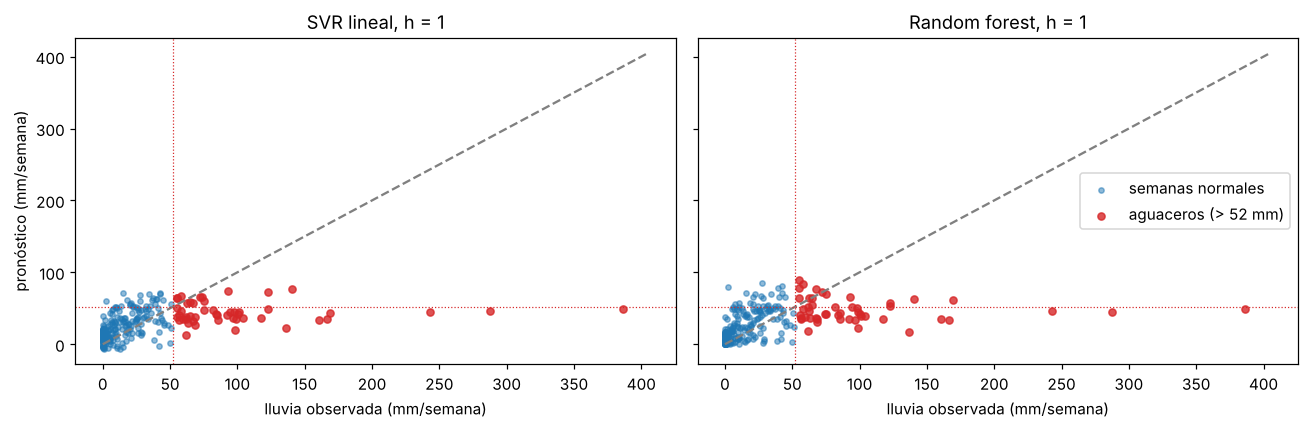

In [15]:
a = AJ[1]; te = a["te"]; umbral = a["tr"].y.quantile(0.90)
fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, col, nombre in [(axs[0], "svr", "SVR lineal"), (axs[1], "rf", "Random forest")]:
    ext = te.y > umbral
    ax.scatter(te.y[~ext], te[col][~ext], s=12, alpha=.5, label="semanas normales")
    ax.scatter(te.y[ext], te[col][ext], s=22, c="C3", alpha=.8, label=f"aguaceros (> {umbral:.0f} mm)")
    lim = max(te.y.max(), te[col].max()) * 1.05
    ax.plot([0, lim], [0, lim], c="grey", ls="--"); ax.axvline(umbral, c="C3", lw=.8, ls=":"); ax.axhline(umbral, c="C3", lw=.8, ls=":")
    ax.set_title(f"{nombre}, h = 1"); ax.set_xlabel("lluvia observada (mm/semana)")
axs[0].set_ylabel("pronóstico (mm/semana)"); axs[1].legend(); plt.tight_layout(); plt.show()

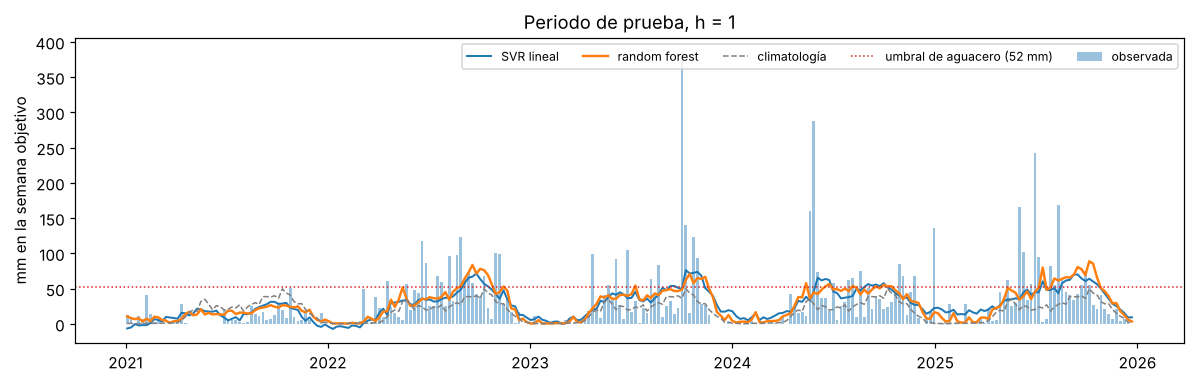

In [16]:
fig, ax = plt.subplots(figsize=(13, 3.6))
ax.bar(te.fecha, te.y, width=5, alpha=.45, label="observada")
ax.plot(te.fecha, te.svr, lw=1.3, label="SVR lineal"); ax.plot(te.fecha, te.rf, lw=1.6, label="random forest")
ax.plot(te.fecha, te.clim, lw=1, ls="--", c="grey", label="climatología")
ax.axhline(umbral, c="C3", ls=":", lw=1, label=f"umbral de aguacero ({umbral:.0f} mm)")
ax.set_ylabel("mm en la semana objetivo"); ax.set_title("Periodo de prueba, h = 1"); ax.legend(ncol=5, fontsize=8); plt.show()

**Interpretación.** En las 49 semanas de aguacero del periodo de prueba (más de 52 mm, percentil 90 de entrenamiento) llovieron en promedio 99,7 mm. La climatología solo anticipa 28,0 mm (28 %), el SVR 44,8 mm (45 %) y el random forest 47,8 mm (48 %) a una semana. La diferencia más clara está en la **detección**: el random forest pronostica más de 52 mm en el 30,6 % de esas semanas a una semana y en el 36,7 % a cuatro semanas, frente a 24,5 % y 20,4 % del SVR. Lo hace con menos falsas alarmas (60,5 % frente a 65,7 % a una semana). El costo es un error algo mayor en las semanas normales (RMSE de 20,1 frente a 19,1 mm a una semana).

Las figuras muestran el límite de ambos modelos: ninguno pronostica más de unos 90 mm por semana, mientras que se observaron semanas de hasta 386 mm. Los modelos detectan **cuándo** es probable una semana muy lluviosa, pero no su **magnitud**. Un árbol pronostica el promedio de las semanas parecidas del entrenamiento, así que no puede extrapolar más allá de lo que vio con frecuencia.

## 4.4 Diagnóstico del random forest (h = 1)

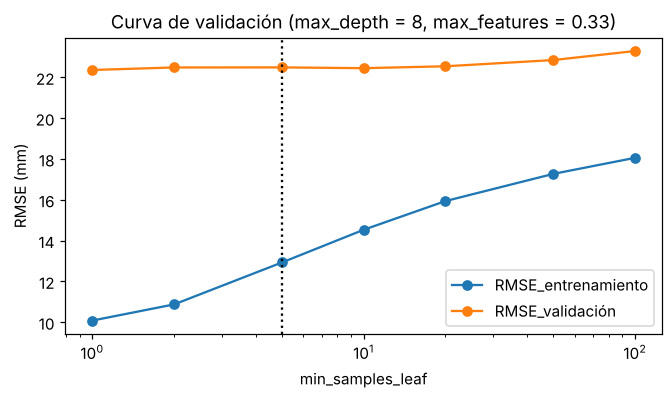

,min_samples_leaf,RMSE_entrenamiento,RMSE_validación
0,1,10.08,22.36
1,2,10.87,22.48
2,5,12.93,22.49
3,10,14.53,22.45
4,20,15.93,22.54
5,50,17.27,22.85
6,100,18.06,23.29


In [19]:
# Curva de validación: error de entrenamiento y de validación según el mínimo de semanas por hoja
a = AJ[1]; tr, cols, sp, mj = a["tr"], a["cols"], a["sp"], a["mejor"]
curva = []
for leaf in [1, 2, 5, 10, 20, 50, 100]:
    et, ev = [], []
    for i_a, i_b in sp:
        m = pipeline_rf(max_depth=mj["max_depth"], min_samples_leaf=leaf, max_features=mj["max_features"]).fit(tr.loc[i_a, cols], tr.loc[i_a, "y"])
        et.append(rmse(tr.loc[i_a, "y"], m.predict(tr.loc[i_a, cols]))); ev.append(rmse(tr.loc[i_b, "y"], m.predict(tr.loc[i_b, cols])))
    curva.append({"min_samples_leaf": leaf, "RMSE_entrenamiento": np.mean(et), "RMSE_validación": np.mean(ev)})
curva = pd.DataFrame(curva)
ax = curva.plot(x="min_samples_leaf", marker="o", logx=True, figsize=(7, 3.5)); ax.axvline(mj["min_samples_leaf"], c="k", ls=":", label="elegido")
ax.set_ylabel("RMSE (mm)"); ax.set_title(f"Curva de validación (max_depth = {mj['max_depth']}, max_features = {mj['max_features']})"); plt.show()
curva.round(2)

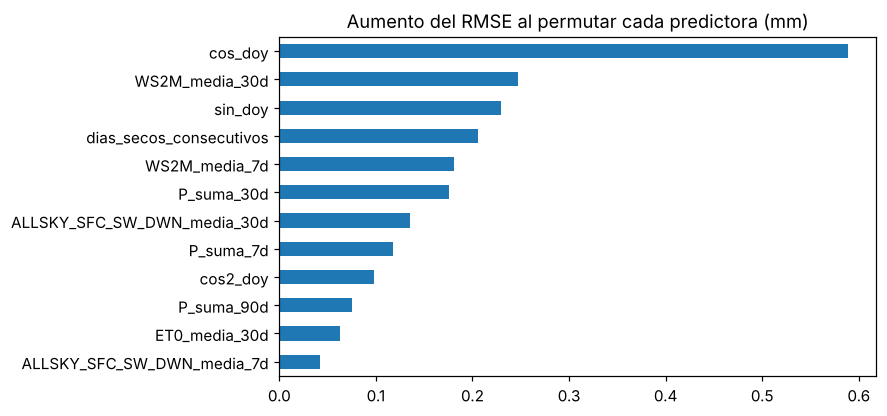

cos_doy                        0.588
WS2M_media_30d                 0.247
sin_doy                        0.229
dias_secos_consecutivos        0.206
WS2M_media_7d                  0.181
P_suma_30d                     0.175
ALLSKY_SFC_SW_DWN_media_30d    0.135
P_suma_7d                      0.117
cos2_doy                       0.098
P_suma_90d                     0.075
dtype: float64

In [20]:
# Importancia por permutación en el último fold de validación (no usa la prueba)
i_a, i_b = sp[-1]
m = pipeline_rf(**mj).fit(tr.loc[i_a, cols], tr.loc[i_a, "y"])
pi = permutation_importance(m, tr.loc[i_b, cols], tr.loc[i_b, "y"], scoring="neg_root_mean_squared_error", n_repeats=20, random_state=cfg.SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=cols).sort_values(ascending=False)
imp.head(12)[::-1].plot.barh(figsize=(7, 4), title="Aumento del RMSE al permutar cada predictora (mm)"); plt.show()
imp.head(10).round(3)

In [21]:
te = AJ[1]["te"].assign(resid_rf=lambda d: d.y - d.rf, resid_svr=lambda d: d.y - d.svr)
diag = pd.DataFrame({
    "media de residuos (mm)": [te.resid_svr.mean(), te.resid_rf.mean()],
    "asimetría de residuos": [stats.skew(te.resid_svr), stats.skew(te.resid_rf)],
    "ACF rezago 1": [pd.Series(te.resid_svr).autocorr(1), pd.Series(te.resid_rf).autocorr(1)],
    "pronóstico máximo (mm)": [te.svr.max(), te.rf.max()],
    "lluvia observada máxima (mm)": [te.y.max(), te.y.max()],
}, index=["SVR lineal", "Random forest"]).T
print(f"Banda de confianza de la ACF: ±{1.96 / np.sqrt(len(te)):.3f}")
diag.round(3)

Banda de confianza de la ACF: ±0.122


,SVR lineal,Random forest
media de residuos (mm),1.937,1.280
asimetría de residuos,3.994,3.878
ACF rezago 1,0.185,0.195
pronóstico máximo (mm),76.285,88.883
lluvia observada máxima (mm),386.040,386.040


**Interpretación.** En la curva de validación, el error de entrenamiento crece de 10,1 a 18,1 mm al exigir más semanas por hoja, mientras que el de validación casi no cambia (de 22,4 a 23,3 mm). La brecha entre ambos es la esperada en un random forest, que se ajusta mucho a su propio entrenamiento. Lo que indica sobreajuste es que el error de **validación** empeore, y eso no ocurre en el rango elegido (5 semanas por hoja, 22,5 mm). Las predictoras más importantes en validación son el ciclo anual (cos_doy y sin_doy), el viento medio de 30 y 7 días, los días secos consecutivos y la lluvia de los últimos 30 días: la misma información que el EDA identificó como asociada a la lluvia de la semana siguiente.

Los residuos del random forest tienen menor sesgo que los del SVR (media de 1,28 frente a 1,94 mm) y un pronóstico máximo mayor (88,9 frente a 76,3 mm). Siguen siendo muy asimétricos (3,88 frente a 3,99) y conservan autocorrelación a un rezago (0,195, por encima de la banda de ±0,122), por la misma razón: los aguaceros extremos no se anticipan.

## 4.5 Cambio de régimen en el periodo de prueba

In [24]:
filas_r = []
for h in [1, 4]:
    te = AJ[h]["te"]
    for nombre, g in [("2021", te[te.fecha.dt.year == 2021]), ("2022–2025", te[te.fecha.dt.year >= 2022])]:
        rc = rmse(g.y, g.clim)
        filas_r.append({"h": h, "periodo": nombre, "lluvia media (mm/sem)": g.y.mean(),
                        "SS SVR": 1 - rmse(g.y, g.svr) / rc, "SS random forest": 1 - rmse(g.y, g.rf) / rc})
pd.DataFrame(filas_r).round(3)

,h,periodo,lluvia media (mm/sem),SS SVR,SS random forest
0,1,2021,8.621,0.249,0.322
1,1,2022–2025,35.019,0.064,0.053
2,4,2021,8.174,0.236,0.286
3,4,2022–2025,35.525,0.046,0.054


**Interpretación.** El cambio de régimen afecta a los dos modelos de forma parecida. En 2021, un año muy seco (8,6 mm por semana), el random forest mejora a la climatología en 32,2 % a una semana, frente a 24,9 % del SVR: reconoce mejor que no va a llover. En 2022–2025, mucho más lluvioso (35,0 mm por semana), la mejora de ambos es pequeña (5,3 % y 6,4 % a una semana; 5,4 % y 4,6 % a cuatro semanas), porque la mayor parte del error está en aguaceros que ningún modelo anticipa.

## 4.6 Random forest frente al SVR en la prueba

Esta sección **describe** cómo se comparan los dos modelos en la prueba 2021–2025, en los horizontes de 1 a 4 semanas. **No elige el modelo final:** elegir mirando la prueba sería ajustar el modelo al examen. La elección se hace en el capítulo 5 con la validación cruzada temporal, donde además se evalúa la combinación de los dos modelos.

In [ ]:
N = 4                                  # horizonte confiable (capítulo 3)
hs = [h for h in cfg.HORIZONTES_SEMANAS if h <= N]
r_svr = res[(res.modelo == "SVR lineal") & res.h.isin(hs)].RMSE.mean()
r_rf = res[(res.modelo == "Random forest") & res.h.isin(hs)].RMSE.mean()
pod = ext_tab[ext_tab.h.isin(hs)].groupby("modelo")["POD"].mean()
print(f"RMSE medio en prueba, h = {hs}: SVR {r_svr:.2f} mm | random forest {r_rf:.2f} mm (diferencia {100 * (r_rf / r_svr - 1):+.1f} %)")
print(f"POD medio de aguaceros en prueba, h = {hs}: SVR {pod['SVR lineal']:.1%} | random forest {pod['Random forest']:.1%}")


**Interpretación.** En la prueba, con horizontes de 1, 2 y 4 semanas, los dos modelos tienen el mismo error medio (40,72 mm), y el random forest detecta más aguaceros (36,7 % frente a 23,8 %). Es una descripción, no una elección: con un periodo de prueba de 5 años tan atípico, estas diferencias pueden ser ruido. El capítulo 5 elige el modelo con la validación, donde además combina el SVR y el random forest en un modelo híbrido.